# Shap Analysis
- Visualization

In [1]:
pip install shap

  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/555.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/555.9 kB ? eta -:--:--
   ---------------------------------------- 555.9/555.9 kB 1.8 MB/s  0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   ---------------------------------------- 0/2 [slicer]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -

In [1]:
pip install catboost

  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/100.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/100.2 MB 2.0 MB/s eta 0:00:49
   ---------------------------------------- 1.0/100.2 MB 2.4 MB/s eta 0:00:42
    --------------------------------------- 1.3/100.2 MB 1.9 MB/s eta 0:00:53
    --------------------------------------- 1.8/100.2 MB 1.8 MB/s eta 0:00:54
    --------------------------------------- 2.1/100.2 MB 1.9 MB/s eta 0:00:53
    --------------------------------------- 2.4/100.2 MB 1.8 MB/s eta 0:00:54
   - -------------------------------------- 2.6/100.2 MB 1.8 MB/s eta 0:00:56
   - -------------------------------------- 2.9/100.2 MB 1.7 MB/s eta 0:00:57
   - -------------------------------------- 2.9/100.2 MB 1.7 MB/s eta 0:00:57
   - -----------------

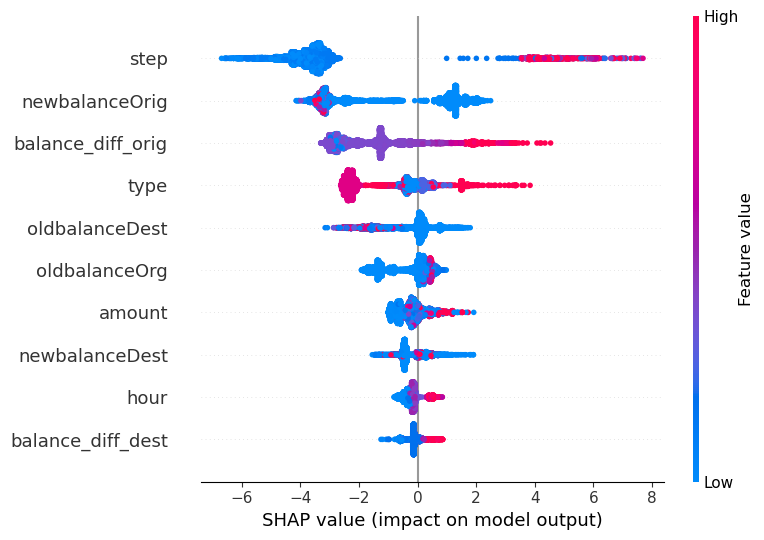

In [13]:

import joblib
import pandas as pd
import shap
from sklearn.preprocessing import LabelEncoder

# Load model
data = joblib.load("best_model.pkl")
model = data["model"]

# Load dataset
df = pd.read_csv(r"C:\Users\DELL\OneDrive\Documents\Fraud_Detection_Project\Data\cleaned_data.csv")

# SAME preprocessing as training
df.drop(['nameOrig', 'nameDest'], axis=1, inplace=True, errors='ignore')

df['isFraud'] = df['isFraud'].astype(int)

df['balance_diff_orig'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['balance_diff_dest'] = df['newbalanceDest'] - df['oldbalanceDest']
df['hour'] = df['step'] % 24

# Encode categorical
le = LabelEncoder()
df['type'] = le.fit_transform(df['type'])

X = df.drop('isFraud', axis=1)

# SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)

shap.summary_plot(shap_values, X)

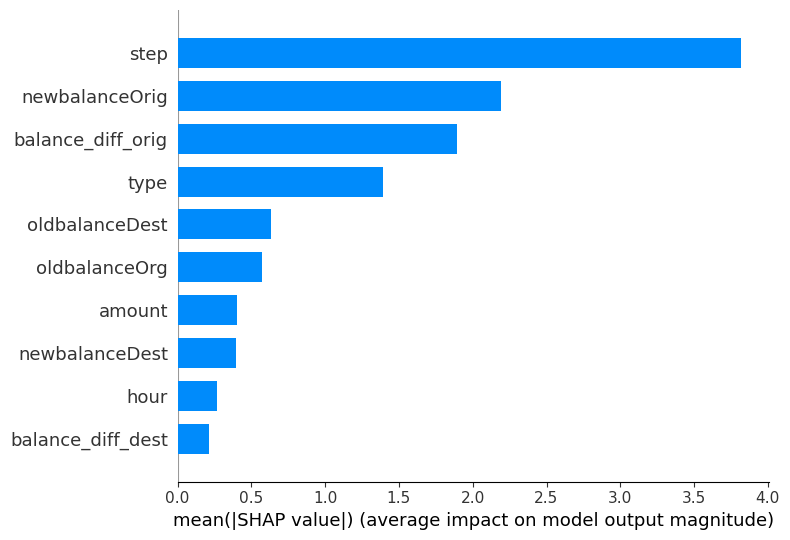

In [14]:
#feature importance bar plot
shap.summary_plot(shap_values, X, plot_type="bar")

In [16]:
import shap
shap.initjs()

In [17]:
shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    X.iloc[0]
)

In [22]:
X.iloc[5]
X.iloc[10]

step                     1.00
type                     1.00
amount               35063.63
oldbalanceOrg        35063.63
newbalanceOrig           0.00
oldbalanceDest       31140.00
newbalanceDest        7550.03
balance_diff_orig    35063.63
balance_diff_dest   -23589.97
hour                     1.00
Name: 10, dtype: float64

In [25]:
# Define i before using it - replace with the index of the row you want to predict
i = 0  # For example, to predict the first row

prob = model.predict_proba(X.iloc[[i]])[:,1][0]
pred = int(prob >= data["threshold"])

print("Prediction:", "Fraud" if pred==1 else "Safe")
print("Probability:", prob)

Prediction: Fraud
Probability: 0.9590289260969892


In [26]:
import pandas as pd

shap_row = pd.DataFrame({
    "feature": X.columns,
    "shap_value": shap_values[i]
}).sort_values(by="shap_value", key=abs, ascending=False)

print(shap_row.head(5))

             feature  shap_value
1               type    3.840981
0               step   -2.770576
7  balance_diff_orig   -1.800995
4     newbalanceOrig    1.501620
2             amount    1.268483


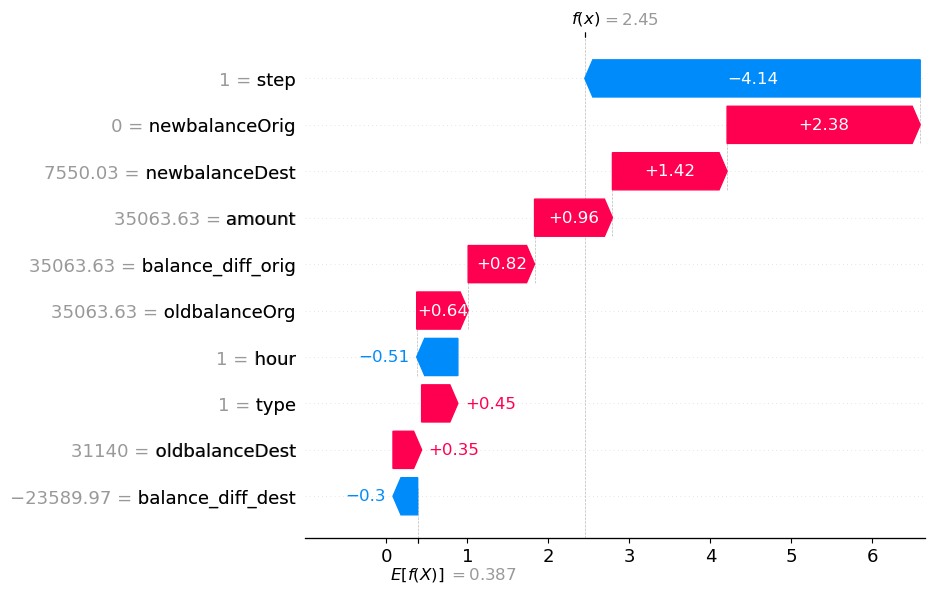

In [27]:
# shape water fall plot
shap.plots.waterfall(shap.Explanation(
    values=shap_values[10],
    base_values=explainer.expected_value,
    data=X.iloc[10]
))